In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

In [2]:
L = tf.keras.layers

In [3]:
df = pd.read_csv("cifar-10.csv",dtype=np.uint8)
df.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [4]:
X = df.drop(columns="label").values.reshape(-1,3,32,32).transpose(0,2,3,1).astype("float32") / 255
Xtr,Xte,ytr,yte = train_test_split(X,df.label.values.astype(int),test_size=0.2,random_state=42)

In [5]:
model = tf.keras.Sequential([L.Flatten(), L.Dense(256, activation="relu"), L.Dense(128, activation="relu"), L.Dense(10, activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=10, batch_size=128, validation_data=(Xte, yte))

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.2528 - loss: 2.0719 - val_accuracy: 0.3576 - val_loss: 1.8219
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.3760 - loss: 1.7623 - val_accuracy: 0.3824 - val_loss: 1.7224
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4089 - loss: 1.6660 - val_accuracy: 0.4187 - val_loss: 1.6251
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4357 - loss: 1.5923 - val_accuracy: 0.4381 - val_loss: 1.5988
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.4490 - loss: 1.5516 - val_accuracy: 0.4426 - val_loss: 1.5706
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4570 - loss: 1.5248 - val_accuracy: 0.4509 - val_loss: 1.5428
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4753 - loss: 1.4792 - val_accuracy: 0.4477 - val_loss: 1.5453
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4748 - loss: 1.4698 - val_accuracy: 0.

In [7]:
print(model.evaluate(Xte, yte))                                  
print(classification_report(yte, model.predict(Xte).argmax(1)))  

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4528 - loss: 1.5132
[1.5107039213180542, 0.45890000462532043]
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       0.47      0.60      0.53       973
           1       0.71      0.35      0.47       979
           2       0.33      0.33      0.33      1030
           3       0.33      0.37      0.35      1023
           4       0.43      0.39      0.41       933
           5       0.39      0.28      0.32      1015
           6       0.52      0.49      0.51       996
           7       0.49      0.52      0.51       994
           8       0.59      0.59      0.59      1017
           9       0.45      0.67      0.54      1040

    accuracy                           0.46     10000
   macro avg       0.47      0.46      0.45     10000
weighted avg       0.47      0.46      0.45     10000



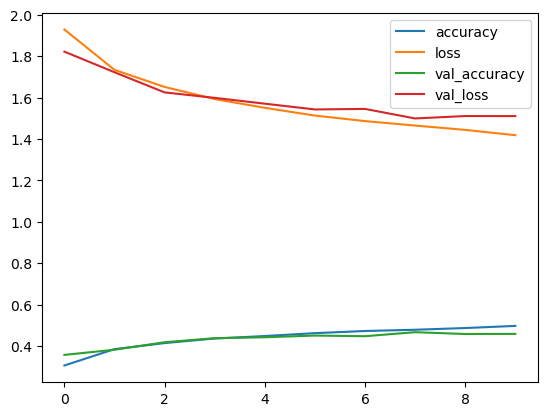

In [8]:
pd.DataFrame(h.history).plot(); 
plt.show()                       

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


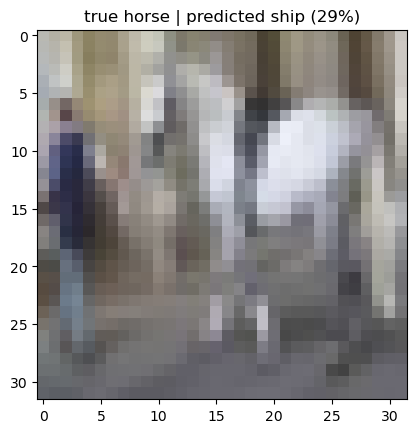

In [9]:
#one example
names = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
i = 0                                                          # any test image
p = model.predict(Xte[i:i+1])[0]                               # one probability per class
plt.imshow(Xte[i].squeeze(), cmap="gray"); plt.title(f"true {names[yte[i]]} | predicted {names[p.argmax()]} ({p.max():.0%})")
plt.show()